# Hierarchical XGBoost — EEG Artifact Classification

Leave-one-subject-out (LOSO) XGBoost pipeline operating on the handcrafted
feature matrix in `features.pkl`. Same hierarchy and evaluation protocol as the
Random Forest notebook (`03_RandomForest.ipynb`) — only the estimator changes.

1. **Stage 1** — artifact vs rest
2. **Stage 2** — ocular vs head/muscle
3. **Stage 3a / 3b** — fine label within each coarse group

A flat 7-class XGBoost and a chained end-to-end pipeline are evaluated alongside
the thresholding baseline (`02_Thresholding.ipynb`) and the Random Forest
chained results (`03_RandomForest.ipynb`).

## Section 1 — Imports & configuration

In [1]:
import pickle
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report,
    precision_recall_fscore_support, roc_auc_score,
)
from xgboost import XGBClassifier

CONFIG = {
    "DATA_DIR": Path("processed_xdf"),
    "OUTPUT_DIR": Path("processed_xdf/04_XGBoost_plots"),
    "RANDOM_STATE": 42,
    # Thresholding baseline results (from 02_Thresholding.ipynb) for comparison.
    "THRESHOLDING_ACC": 0.7759,
    "THRESHOLDING_F1":  0.7706,
    # Random Forest chained results (from 03_RandomForest.ipynb) for comparison.
    "RF_CHAINED_ACC":   0.7259,
    "RF_CHAINED_F1":    0.6196,
}

XGB_KWARGS = dict(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)

# Exact label sets each stage is allowed to see and predict.
STAGE2_LABELS  = ("ocular", "head_muscle")
STAGE3A_LABELS = ("blink", "look_left", "look_right")
STAGE3B_LABELS = ("horiz_head", "vert_head", "clench")

CONFIG["OUTPUT_DIR"].mkdir(parents=True, exist_ok=True)
CONFIG["DATA_DIR"].mkdir(parents=True, exist_ok=True)
sns.set_context("notebook")
print("Configuration ready.")

Configuration ready.


## Section 2 — Load data & LOSO setup

In [2]:
# Load the handcrafted feature matrix (XGBoost uses features only — no raw windows).
features_path = CONFIG["DATA_DIR"] / "features.pkl"
print(f"Loading {features_path}")
with features_path.open("rb") as f:
    bundle = pickle.load(f)

X             = bundle["X"]
y_fine        = bundle["y_fine"]
y_level1      = bundle["y_level1"]
y_level2      = bundle["y_level2"]
subject_ids   = bundle["subject_ids"]
feature_names = bundle["feature_names"]

# Replace None in y_level2 with the sentinel string 'none' so it can be used as
# a plain string array for filtering.
y_level2_for_enc = np.array(
    [lbl if lbl is not None else "none" for lbl in y_level2], dtype=object)

print(f"X.shape         : {X.shape}")
print(f"feature_names   : {len(feature_names)} entries")
print(f"unique subjects : {len(np.unique(subject_ids))}")


def _class_distribution_table(
    labels: np.ndarray, subjects: np.ndarray, title: str,
) -> None:
    """Print the overall and per-subject distribution for a label array."""
    print(f"\n=== {title} ===")
    overall = pd.Series(labels).value_counts(dropna=False)
    pct = (overall / overall.sum() * 100).round(1)
    print("Overall:")
    print(pd.DataFrame({"count": overall, "pct": pct}).to_string())

    per_subj = (
        pd.DataFrame({"subject_id": subjects, "label": labels})
        .assign(count=1)
        .pivot_table(index="subject_id", columns="label",
                     values="count", aggfunc="sum", fill_value=0)
    )
    per_subj["TOTAL"] = per_subj.sum(axis=1)
    print("\nPer subject:")
    print(per_subj.to_string())


_class_distribution_table(y_level1, subject_ids, "Level 1 (artifact / rest)")
_class_distribution_table(y_level2_for_enc, subject_ids,
                          "Level 2 (ocular / head_muscle / none)")
_class_distribution_table(y_fine, subject_ids, "Fine label")

Loading processed_xdf\features.pkl
X.shape         : (11418, 324)
feature_names   : 324 entries
unique subjects : 13

=== Level 1 (artifact / rest) ===
Overall:
          count   pct
artifact   5907  51.7
rest       5511  48.3

Per subject:
label         artifact  rest  TOTAL
subject_id                         
sub-0b11bec3       456   424    880
sub-123051bf       457   424    881
sub-160f8068       456   424    880
sub-2cbce981       438   424    862
sub-3f0ec71e       450   420    870
sub-413e6462       456   424    880
sub-81091e67       457   424    881
sub-9c5349dc       456   425    881
sub-b835837a       456   424    880
sub-bf3d1a74       456   424    880
sub-d0bb067d       457   424    881
sub-ece8d790       456   425    881
sub-f415eee8       456   425    881

=== Level 2 (ocular / head_muscle / none) ===
Overall:
             count   pct
none          5511  48.3
ocular        2963  26.0
head_muscle   2944  25.8

Per subject:
label         head_muscle  none  ocular  TOTAL
su

In [3]:
# LOSO folds — one fold per subject.
LOSO_SUBJECTS = sorted(np.unique(subject_ids))
print(f"LOSO folds ({len(LOSO_SUBJECTS)}): {LOSO_SUBJECTS}")


def loso_fold(test_subject: str) -> tuple[np.ndarray, np.ndarray]:
    """Return (train_idx, test_idx) row indices for one leave-one-subject-out fold."""
    test_idx  = np.where(subject_ids == test_subject)[0]
    train_idx = np.where(subject_ids != test_subject)[0]
    return train_idx, test_idx

LOSO folds (13): ['sub-0b11bec3', 'sub-123051bf', 'sub-160f8068', 'sub-2cbce981', 'sub-3f0ec71e', 'sub-413e6462', 'sub-81091e67', 'sub-9c5349dc', 'sub-b835837a', 'sub-bf3d1a74', 'sub-d0bb067d', 'sub-ece8d790', 'sub-f415eee8']


## Section 3 — Label encoding & helper functions

XGBoost requires integer class targets in the contiguous range `[0, n_classes)`.
We fit global `LabelEncoder`s on the full label sets so predictions can be
decoded back to strings for evaluation. Stage 1 (binary) and the flat 7-class
model use these directly. The per-stage *subset* models (Stage 2 / 3a / 3b)
train on only a subset of classes, so they additionally use a **local** encoder
fitted on that subset inside the loop — a global encoder would yield
non-contiguous integers (e.g. `[0, 3, 4]`), which XGBoost rejects.

In [4]:
# Global label encoders — XGBoost needs integer targets; we decode back to
# strings for all reporting.
le_fine   = LabelEncoder().fit(y_fine)
le_level1 = LabelEncoder().fit(y_level1)
le_level2 = LabelEncoder().fit(
    [l for l in y_level2 if l is not None] + ["none"])

y_fine_enc   = le_fine.transform(y_fine)
y_level1_enc = le_level1.transform(y_level1)
y_level2_enc = np.array([
    le_level2.transform([l if l is not None else "none"])[0]
    for l in y_level2
])

print("Label encoders ready.")
print(f"  fine   classes: {list(le_fine.classes_)}")
print(f"  level1 classes: {list(le_level1.classes_)}")
print(f"  level2 classes: {list(le_level2.classes_)}")

Label encoders ready.
  fine   classes: ['blink', 'clench', 'horiz_head', 'look_left', 'look_right', 'rest', 'vert_head']
  level1 classes: ['artifact', 'rest']
  level2 classes: [np.str_('head_muscle'), np.str_('none'), np.str_('ocular')]


In [5]:
# Random generator shared by the downsampler — fixed for reproducibility.
RNG = np.random.default_rng(CONFIG["RANDOM_STATE"])


def balanced_train_indices(train_idx: np.ndarray) -> np.ndarray:
    """Downsample rest windows in a training fold to match the artifact count.

    Parameters
    ----------
    train_idx : numpy.ndarray
        Indices into the global feature matrix for the training fold.

    Returns
    -------
    numpy.ndarray
        Subset of ``train_idx`` containing all artifact windows + an equal-sized
        random sample of rest windows (the same random state across folds gives
        reproducibility).
    """
    fold_l1 = y_level1[train_idx]
    artifact_local = np.where(fold_l1 == "artifact")[0]
    rest_local     = np.where(fold_l1 == "rest")[0]

    n_artifact = len(artifact_local)
    n_rest_keep = min(n_artifact, len(rest_local))

    rest_sample = RNG.choice(rest_local, size=n_rest_keep, replace=False)
    balanced_local = np.concatenate([artifact_local, rest_sample])
    return train_idx[balanced_local]


def plot_confusion(
    cm: np.ndarray, labels: list[str], title: str, cmap: str,
    fname: str, normalise: bool = True,
) -> None:
    """Plot and save a confusion-matrix heatmap.

    Parameters
    ----------
    cm : numpy.ndarray
        Confusion matrix from ``sklearn.metrics.confusion_matrix``.
    labels : list of str
        Class names, in the same order as the rows/columns of ``cm``.
    title : str
        Plot title.
    cmap : str
        Seaborn/matplotlib colormap name.
    fname : str
        Output file name, saved under ``CONFIG['OUTPUT_DIR']``.
    normalise : bool, default True
        If True, divide each row by its sum so cells show per-class recall.
    """
    if normalise:
        row_sums = cm.sum(axis=1, keepdims=True)
        data = cm / np.clip(row_sums, 1, None)
        fmt = ".2f"
    else:
        data = cm
        fmt = "d"

    fig, ax = plt.subplots(figsize=(0.9 * len(labels) + 2.5,
                                    0.8 * len(labels) + 2))
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap,
                xticklabels=labels, yticklabels=labels,
                vmin=0 if normalise else None,
                vmax=1 if normalise else None, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=40)
    fig.tight_layout()
    fig.savefig(CONFIG["OUTPUT_DIR"] / fname, dpi=140)
    plt.show()

## Section 4 — LOSO training loop

Trains the four per-stage XGBoost models + a flat 7-class XGBoost on every fold,
and runs chained inference (Stage 1 -> 2 -> 3a/3b) per test window. Downsampling
and the scaler are fit on the training fold only — no leakage across subjects.
All targets are integer-encoded for XGBoost and decoded back to strings before
evaluation.

In [6]:
# Accumulators for predictions and per-fold importances.
fold_results: list[dict] = []
true_fine_all:    list[str] = []
pred_chain_all:   list[str] = []
pred_flat_all:    list[str] = []
pred_stage1_all:  list[str] = []          # binary
pred_stage1_prob_all: list[float] = []     # P(artifact)

# Stage-specific accumulators — populated only with windows that pass each
# stage's true-label filter (no spurious extra classes).
true_stage2_all:  list[str] = []
pred_stage2_all:  list[str] = []
true_stage3a_all: list[str] = []
pred_stage3a_all: list[str] = []
true_stage3b_all: list[str] = []
pred_stage3b_all: list[str] = []

stage_importances = defaultdict(list)      # stage -> list of (n_features,) arrays
stage_f1_per_subject = defaultdict(dict)   # stage -> {subject: f1}

print(f"Running LOSO-CV across {len(LOSO_SUBJECTS)} subjects...")

for fi, test_subject in enumerate(LOSO_SUBJECTS, 1):
    train_idx, test_idx = loso_fold(test_subject)
    bal_idx = balanced_train_indices(train_idx)

    X_train_bal = X[bal_idx]
    X_test      = X[test_idx]

    # Standard scaler — fitted but not applied to XGBoost (kept for future use).
    _scaler = StandardScaler().fit(X_train_bal)

    # ---- Stage 1: artifact vs rest (global level-1 encoder) ----
    y_train_s1 = y_level1_enc[bal_idx]
    y_test_s1  = y_level1[test_idx]
    xgb_s1 = XGBClassifier(**XGB_KWARGS)
    xgb_s1.fit(X_train_bal, y_train_s1)
    s1_pred = le_level1.inverse_transform(xgb_s1.predict(X_test))
    s1_proba = xgb_s1.predict_proba(X_test)
    # predict_proba columns follow xgb.classes_ (encoded ints) — decode them to
    # locate the artifact column, mirroring the RF notebook's use of classes_.
    s1_classes = list(le_level1.inverse_transform(xgb_s1.classes_))
    s1_artifact_col = s1_classes.index("artifact")
    s1_prob_artifact = s1_proba[:, s1_artifact_col]
    stage_importances["stage1"].append(xgb_s1.feature_importances_)

    # ---- Stage 2: ocular vs head_muscle (filtered to exactly 2 classes) ----
    bal_s2_mask = np.isin(y_level2_for_enc[bal_idx], STAGE2_LABELS)
    X_train_s2 = X[bal_idx][bal_s2_mask]
    y_train_s2_str = y_level2_for_enc[bal_idx][bal_s2_mask]
    le_s2 = LabelEncoder().fit(y_train_s2_str)     # local: contiguous 0..1
    xgb_s2 = XGBClassifier(**XGB_KWARGS)
    xgb_s2.fit(X_train_s2, le_s2.transform(y_train_s2_str))
    stage_importances["stage2"].append(xgb_s2.feature_importances_)

    # Test subset: windows whose TRUE level-2 is exactly ocular/head_muscle.
    s2_test_mask = np.isin(y_level2_for_enc[test_idx], STAGE2_LABELS)
    if s2_test_mask.any():
        X_test_s2 = X_test[s2_test_mask]
        y_true_s2 = y_level2_for_enc[test_idx][s2_test_mask]
        s2_pred_direct = le_s2.inverse_transform(xgb_s2.predict(X_test_s2))
    else:
        y_true_s2 = np.empty(0, dtype=object)
        s2_pred_direct = np.empty(0, dtype=object)

    # ---- Stage 3a: fine ocular (filtered to exactly 3 classes) ----
    bal_s3a_mask = np.isin(y_fine[bal_idx], STAGE3A_LABELS)
    X_train_s3a = X[bal_idx][bal_s3a_mask]
    y_train_s3a_str = y_fine[bal_idx][bal_s3a_mask]
    le_s3a = LabelEncoder().fit(y_train_s3a_str)
    xgb_s3a = XGBClassifier(**XGB_KWARGS)
    xgb_s3a.fit(X_train_s3a, le_s3a.transform(y_train_s3a_str))
    stage_importances["stage3a"].append(xgb_s3a.feature_importances_)

    s3a_test_mask = np.isin(y_fine[test_idx], STAGE3A_LABELS)
    if s3a_test_mask.any():
        X_test_s3a = X_test[s3a_test_mask]
        y_true_s3a = y_fine[test_idx][s3a_test_mask]
        s3a_pred_direct = le_s3a.inverse_transform(xgb_s3a.predict(X_test_s3a))
    else:
        y_true_s3a = np.empty(0, dtype=object)
        s3a_pred_direct = np.empty(0, dtype=object)

    # ---- Stage 3b: fine head/muscle (filtered to exactly 3 classes) ----
    bal_s3b_mask = np.isin(y_fine[bal_idx], STAGE3B_LABELS)
    X_train_s3b = X[bal_idx][bal_s3b_mask]
    y_train_s3b_str = y_fine[bal_idx][bal_s3b_mask]
    le_s3b = LabelEncoder().fit(y_train_s3b_str)
    xgb_s3b = XGBClassifier(**XGB_KWARGS)
    xgb_s3b.fit(X_train_s3b, le_s3b.transform(y_train_s3b_str))
    stage_importances["stage3b"].append(xgb_s3b.feature_importances_)

    s3b_test_mask = np.isin(y_fine[test_idx], STAGE3B_LABELS)
    if s3b_test_mask.any():
        X_test_s3b = X_test[s3b_test_mask]
        y_true_s3b = y_fine[test_idx][s3b_test_mask]
        s3b_pred_direct = le_s3b.inverse_transform(xgb_s3b.predict(X_test_s3b))
    else:
        y_true_s3b = np.empty(0, dtype=object)
        s3b_pred_direct = np.empty(0, dtype=object)

    # ---- Flat XGBoost baseline (global fine encoder) ----
    xgb_flat = XGBClassifier(**XGB_KWARGS)
    xgb_flat.fit(X_train_bal, y_fine_enc[bal_idx])
    pred_flat = le_fine.inverse_transform(xgb_flat.predict(X_test))
    stage_importances["flat"].append(xgb_flat.feature_importances_)

    # ---- Chained inference per test window ----
    chain_pred = np.empty(len(test_idx), dtype=object)
    for i in range(len(test_idx)):
        if s1_pred[i] == "rest":
            chain_pred[i] = "rest"
            continue
        # Predict coarse group
        s2_pred = le_s2.inverse_transform(xgb_s2.predict(X_test[[i]]))[0]
        if s2_pred == "ocular":
            chain_pred[i] = le_s3a.inverse_transform(xgb_s3a.predict(X_test[[i]]))[0]
        elif s2_pred == "head_muscle":
            chain_pred[i] = le_s3b.inverse_transform(xgb_s3b.predict(X_test[[i]]))[0]
        else:
            chain_pred[i] = "unknown_artifact"

    # Per-fold metric (Stage 1 F1 macro).
    fold_f1_s1 = f1_score(y_test_s1, s1_pred, average="macro")
    fold_acc_s1 = accuracy_score(y_test_s1, s1_pred)
    stage_f1_per_subject["stage1"][test_subject] = fold_f1_s1

    fold_results.append({
        "subject":   test_subject,
        "n_test":    int(len(test_idx)),
        "n_train_balanced": int(len(bal_idx)),
        "stage1_f1": fold_f1_s1,
        "stage1_acc": fold_acc_s1,
        "stage1_proba_artifact": s1_prob_artifact,
        "stage1_pred": s1_pred,
        "stage1_true": y_test_s1,
        "chain_pred": chain_pred,
        "flat_pred": pred_flat,
        "test_idx":  test_idx,
    })

    true_fine_all.extend(y_fine[test_idx].tolist())
    pred_chain_all.extend(chain_pred.tolist())
    pred_flat_all.extend(pred_flat.tolist())
    pred_stage1_all.extend(s1_pred.tolist())
    pred_stage1_prob_all.extend(s1_prob_artifact.tolist())

    true_stage2_all.extend(y_true_s2.tolist())
    pred_stage2_all.extend(s2_pred_direct.tolist())
    true_stage3a_all.extend(y_true_s3a.tolist())
    pred_stage3a_all.extend(s3a_pred_direct.tolist())
    true_stage3b_all.extend(y_true_s3b.tolist())
    pred_stage3b_all.extend(s3b_pred_direct.tolist())

    print(f"  fold {fi}/{len(LOSO_SUBJECTS)}  subject={test_subject:>16s}  "
          f"n_test={len(test_idx):4d}  stage1_f1={fold_f1_s1:.3f}")

true_fine_all    = np.asarray(true_fine_all)
pred_chain_all   = np.asarray(pred_chain_all)
pred_flat_all    = np.asarray(pred_flat_all)
pred_stage1_all  = np.asarray(pred_stage1_all)
pred_stage1_prob_all = np.asarray(pred_stage1_prob_all)

true_stage2_all  = np.asarray(true_stage2_all,  dtype=object)
pred_stage2_all  = np.asarray(pred_stage2_all,  dtype=object)
true_stage3a_all = np.asarray(true_stage3a_all, dtype=object)
pred_stage3a_all = np.asarray(pred_stage3a_all, dtype=object)
true_stage3b_all = np.asarray(true_stage3b_all, dtype=object)
pred_stage3b_all = np.asarray(pred_stage3b_all, dtype=object)

print("\nLOSO loop complete.")

Running LOSO-CV across 13 subjects...
  fold 1/13  subject=    sub-0b11bec3  n_test= 880  stage1_f1=0.892
  fold 2/13  subject=    sub-123051bf  n_test= 881  stage1_f1=0.968
  fold 3/13  subject=    sub-160f8068  n_test= 880  stage1_f1=0.907
  fold 4/13  subject=    sub-2cbce981  n_test= 862  stage1_f1=0.812
  fold 5/13  subject=    sub-3f0ec71e  n_test= 870  stage1_f1=0.881
  fold 6/13  subject=    sub-413e6462  n_test= 880  stage1_f1=0.870
  fold 7/13  subject=    sub-81091e67  n_test= 881  stage1_f1=0.920
  fold 8/13  subject=    sub-9c5349dc  n_test= 881  stage1_f1=0.902
  fold 9/13  subject=    sub-b835837a  n_test= 880  stage1_f1=0.908
  fold 10/13  subject=    sub-bf3d1a74  n_test= 880  stage1_f1=0.689
  fold 11/13  subject=    sub-d0bb067d  n_test= 881  stage1_f1=0.857
  fold 12/13  subject=    sub-ece8d790  n_test= 881  stage1_f1=0.915
  fold 13/13  subject=    sub-f415eee8  n_test= 881  stage1_f1=0.922

LOSO loop complete.


## Section 5 — Per-stage evaluation

Stage 1 (artifact vs rest) — LOSO aggregate
  Accuracy : 0.8808
  F1 macro : 0.8808
  ROC-AUC  : 0.9538
              precision    recall  f1-score   support

        rest      0.859     0.901     0.879      5511
    artifact      0.903     0.862     0.882      5907

    accuracy                          0.881     11418
   macro avg      0.881     0.881     0.881     11418
weighted avg      0.882     0.881     0.881     11418



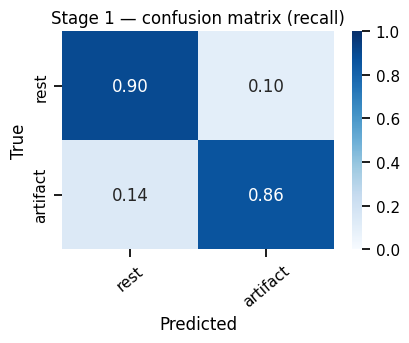

In [7]:
# ---- Stage 1: artifact vs rest ----
true_l1_all = np.array(["rest" if t == "rest" else "artifact" for t in true_fine_all])

s1_acc = accuracy_score(true_l1_all, pred_stage1_all)
s1_f1  = f1_score(true_l1_all, pred_stage1_all, average="macro")
y_true_bin = (true_l1_all == "artifact").astype(int)
s1_auc = roc_auc_score(y_true_bin, pred_stage1_prob_all)

print("Stage 1 (artifact vs rest) — LOSO aggregate")
print(f"  Accuracy : {s1_acc:.4f}")
print(f"  F1 macro : {s1_f1:.4f}")
print(f"  ROC-AUC  : {s1_auc:.4f}")
print(classification_report(true_l1_all, pred_stage1_all,
                            labels=["rest", "artifact"], digits=3))

s1_cm = confusion_matrix(true_l1_all, pred_stage1_all, labels=["rest", "artifact"])
plot_confusion(s1_cm, ["rest", "artifact"],
               "Stage 1 — confusion matrix (recall)",
               "Blues", "xgb_stage1_confusion.png", normalise=True)

Stage 2 (ocular vs head_muscle) — pooled across folds
  n test windows : 5907
  Accuracy       : 0.9350
  F1 macro       : 0.9350
              precision    recall  f1-score   support

      ocular      0.925     0.948     0.936      2963
 head_muscle      0.946     0.922     0.934      2944

    accuracy                          0.935      5907
   macro avg      0.935     0.935     0.935      5907
weighted avg      0.935     0.935     0.935      5907



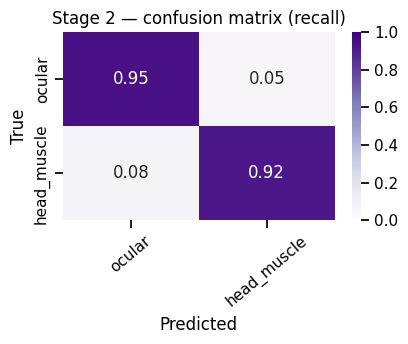

In [8]:
# ---- Stage 2: ocular vs head_muscle (pooled over true-label test windows) ----
s2_labels = list(STAGE2_LABELS)
s2_acc = accuracy_score(true_stage2_all, pred_stage2_all)
s2_f1  = f1_score(true_stage2_all, pred_stage2_all, average="macro",
                  labels=s2_labels, zero_division=0)

print("Stage 2 (ocular vs head_muscle) — pooled across folds")
print(f"  n test windows : {len(true_stage2_all)}")
print(f"  Accuracy       : {s2_acc:.4f}")
print(f"  F1 macro       : {s2_f1:.4f}")
print(classification_report(true_stage2_all, pred_stage2_all,
                            labels=s2_labels, digits=3, zero_division=0))

s2_cm = confusion_matrix(true_stage2_all, pred_stage2_all, labels=s2_labels)
plot_confusion(s2_cm, s2_labels, "Stage 2 — confusion matrix (recall)",
               "Purples", "xgb_stage2_confusion.png", normalise=True)


Stage 3a (fine ocular) — pooled across folds
  n test windows : 2963
  Accuracy       : 0.8309
  F1 macro       : 0.8309
              precision    recall  f1-score   support

       blink      0.802     0.810     0.806       988
   look_left      0.857     0.817     0.836       988
  look_right      0.835     0.866     0.850       987

    accuracy                          0.831      2963
   macro avg      0.831     0.831     0.831      2963
weighted avg      0.831     0.831     0.831      2963



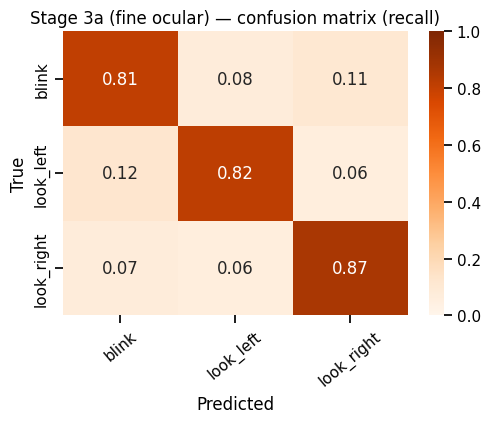


Stage 3b (fine head/muscle) — pooled across folds
  n test windows : 2944
  Accuracy       : 0.6936
  F1 macro       : 0.6921
              precision    recall  f1-score   support

      clench      0.673     0.660     0.666       970
  horiz_head      0.716     0.783     0.748       987
   vert_head      0.689     0.637     0.662       987

    accuracy                          0.694      2944
   macro avg      0.693     0.693     0.692      2944
weighted avg      0.693     0.694     0.692      2944



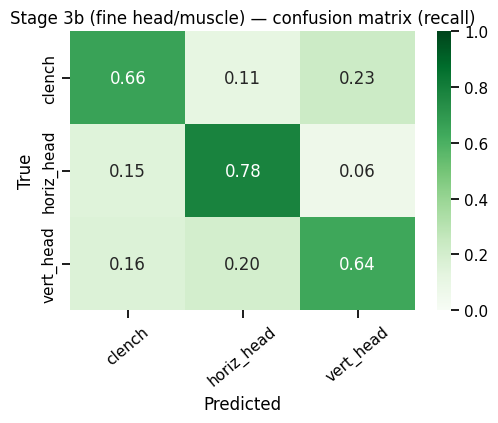

In [9]:
# ---- Stage 3a and 3b: fine label within each coarse group ----
def _evaluate_stage(
    y_true: np.ndarray, y_pred: np.ndarray, labels_sorted: list[str],
    title: str, cmap: str, fname: str,
) -> tuple[float, float]:
    """Print metrics + confusion matrix for one fine-grained stage; return (acc, f1)."""
    if len(y_true) == 0:
        print(f"{title}: no test windows in this subset.")
        return float("nan"), float("nan")
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro",
                   labels=labels_sorted, zero_division=0)
    print(f"\n{title} — pooled across folds")
    print(f"  n test windows : {len(y_true)}")
    print(f"  Accuracy       : {acc:.4f}")
    print(f"  F1 macro       : {f1m:.4f}")
    print(classification_report(y_true, y_pred, labels=labels_sorted,
                                digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)
    plot_confusion(cm, labels_sorted, f"{title} — confusion matrix (recall)",
                   cmap, fname, normalise=True)
    return acc, f1m


s3a_acc, s3a_f1 = _evaluate_stage(
    true_stage3a_all, pred_stage3a_all, sorted(STAGE3A_LABELS),
    "Stage 3a (fine ocular)", "Oranges", "xgb_stage3a_confusion.png")
s3b_acc, s3b_f1 = _evaluate_stage(
    true_stage3b_all, pred_stage3b_all, sorted(STAGE3B_LABELS),
    "Stage 3b (fine head/muscle)", "Greens", "xgb_stage3b_confusion.png")

Flat XGBoost  — accuracy 0.7530  F1 macro 0.6522
Chained chain — accuracy 0.7499  F1 macro 0.6576

Flat XGBoost classification report:
              precision    recall  f1-score   support

       blink      0.488     0.277     0.354       988
      clench      0.684     0.576     0.626       970
  horiz_head      0.635     0.619     0.627       987
   look_left      0.845     0.670     0.748       988
  look_right      0.816     0.683     0.744       987
        rest      0.801     0.952     0.870      5511
   vert_head      0.620     0.578     0.598       987

    accuracy                          0.753     11418
   macro avg      0.699     0.622     0.652     11418
weighted avg      0.739     0.753     0.739     11418


Chained pipeline classification report:
              precision    recall  f1-score   support

       blink      0.433     0.351     0.388       988
      clench      0.605     0.629     0.617       970
  horiz_head      0.623     0.690     0.655       987
   look_le

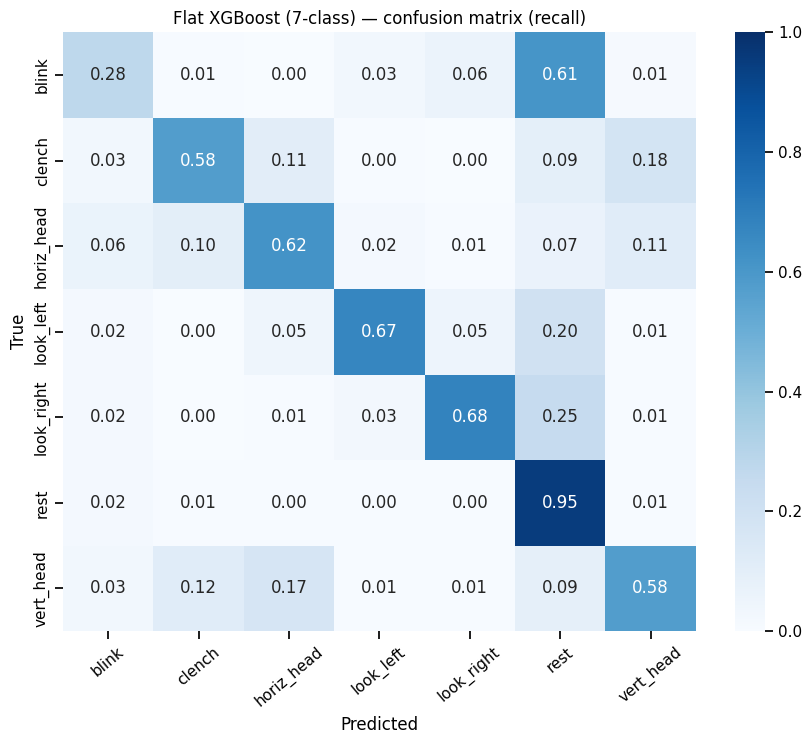

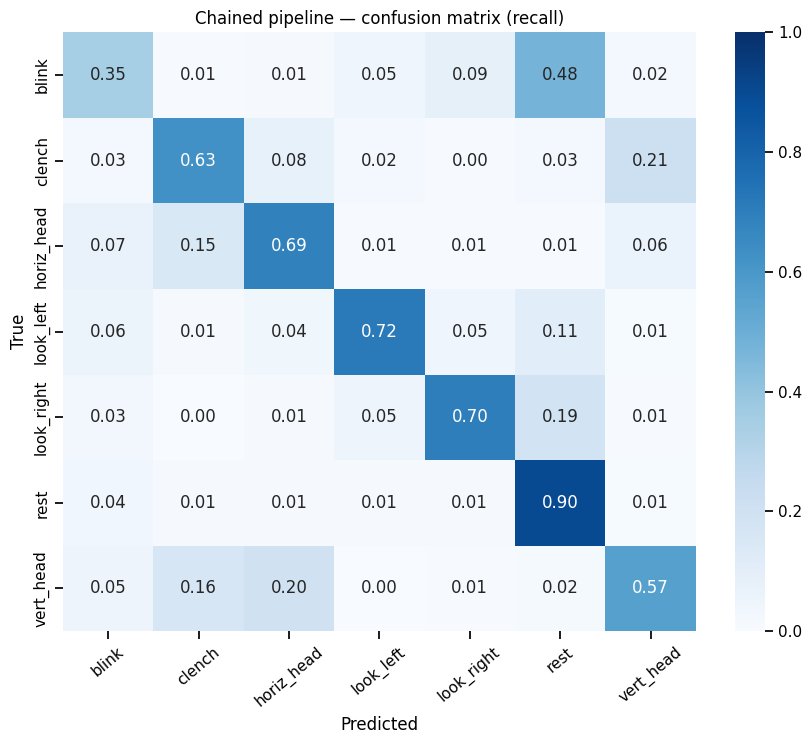

In [10]:
# ---- Flat XGBoost baseline and chained pipeline, end-to-end (7-class) ----
all_fine_labels = sorted(set(true_fine_all.tolist()) | {"rest"})

flat_acc = accuracy_score(true_fine_all, pred_flat_all)
flat_f1  = f1_score(true_fine_all, pred_flat_all, average="macro",
                    labels=all_fine_labels, zero_division=0)
chain_acc = accuracy_score(true_fine_all, pred_chain_all)
chain_f1  = f1_score(true_fine_all, pred_chain_all, average="macro",
                     labels=all_fine_labels, zero_division=0)

print(f"Flat XGBoost  — accuracy {flat_acc:.4f}  F1 macro {flat_f1:.4f}")
print(f"Chained chain — accuracy {chain_acc:.4f}  F1 macro {chain_f1:.4f}")

print("\nFlat XGBoost classification report:")
print(classification_report(true_fine_all, pred_flat_all,
                            labels=all_fine_labels, digits=3, zero_division=0))
print("\nChained pipeline classification report:")
print(classification_report(true_fine_all, pred_chain_all,
                            labels=all_fine_labels, digits=3, zero_division=0))

flat_cm = confusion_matrix(true_fine_all, pred_flat_all, labels=all_fine_labels)
plot_confusion(flat_cm, all_fine_labels,
               "Flat XGBoost (7-class) — confusion matrix (recall)",
               "Blues", "xgb_flat_confusion.png", normalise=True)

chain_cm = confusion_matrix(true_fine_all, pred_chain_all, labels=all_fine_labels)
plot_confusion(chain_cm, all_fine_labels,
               "Chained pipeline — confusion matrix (recall)",
               "Blues", "xgb_chained_confusion.png", normalise=True)

## Section 6 — Feature importance

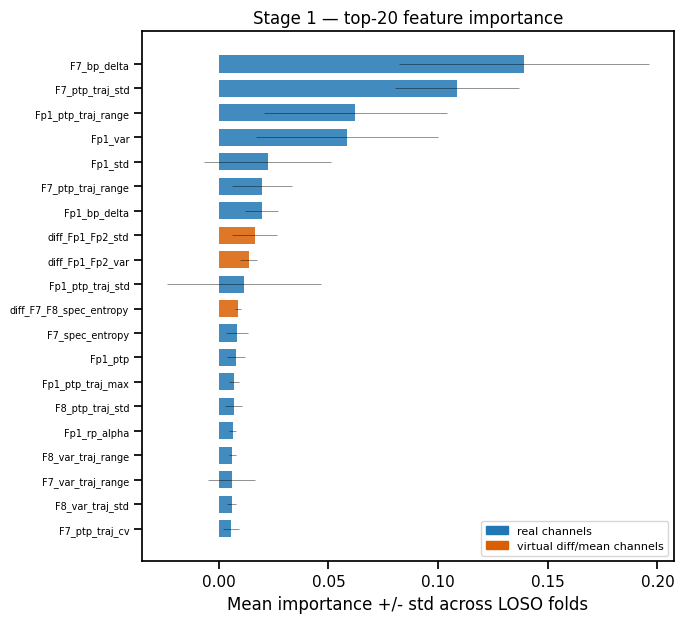

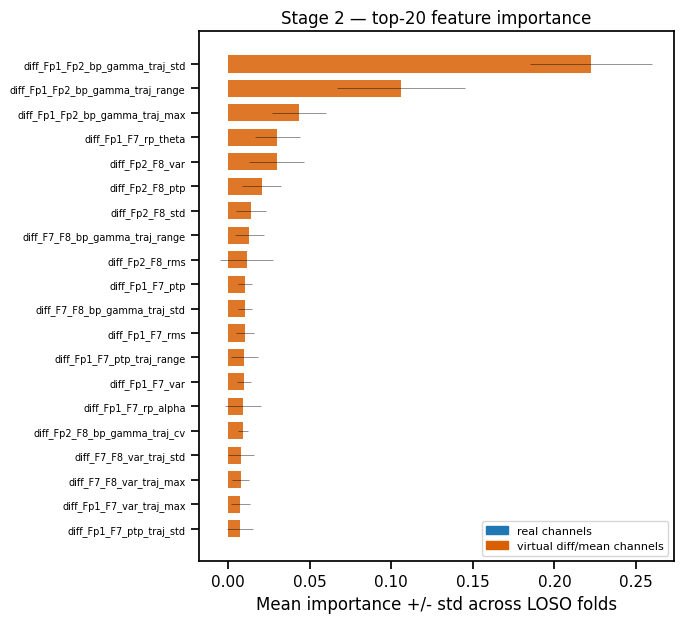

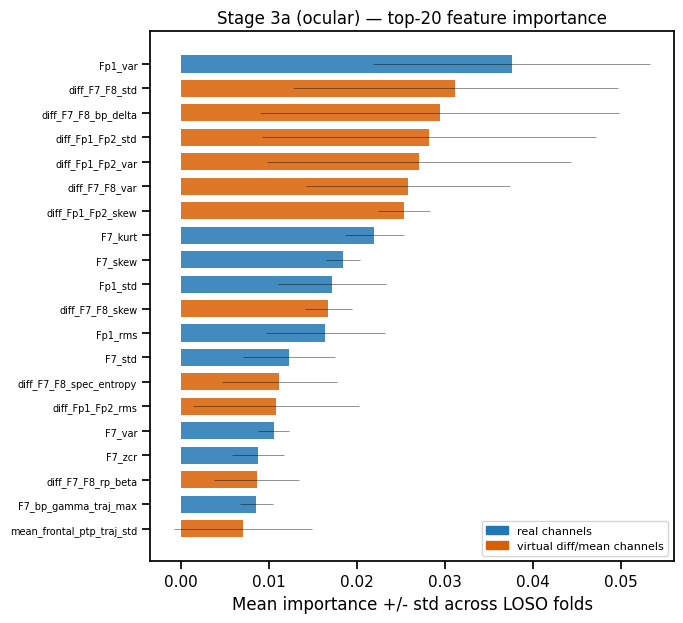

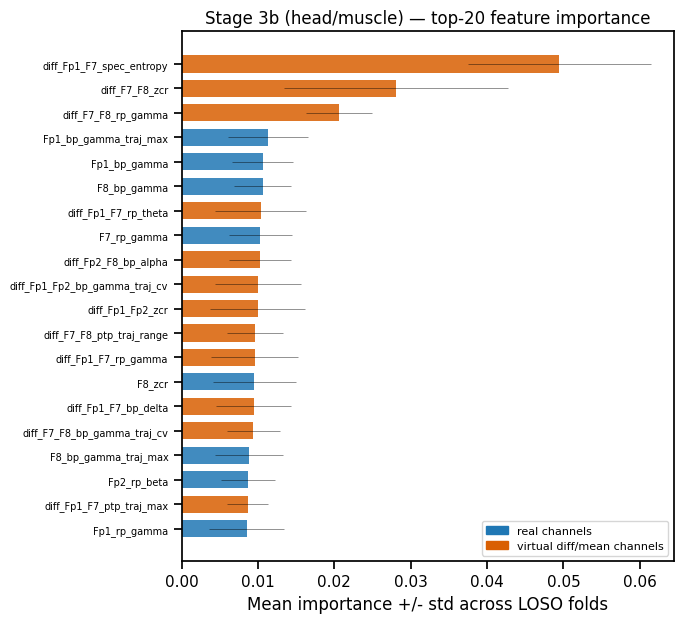

Virtual vs real channel importance share (sums to 1.0 per stage):
  Stage  Virtual share  Real share
 stage1          0.290       0.710
 stage2          0.824       0.176
stage3a          0.535       0.465
stage3b          0.597       0.403


In [11]:
# ---- Per-stage feature importance (aggregated across LOSO folds) ----
def _is_virtual(name: str) -> bool:
    """True if a feature comes from a virtual (diff / mean-frontal) channel."""
    return name.startswith("diff_") or name.startswith("mean_frontal")


def _plot_stage_importance(
    stage_key: str, title: str, fname: str, top_n: int = 20,
) -> pd.DataFrame:
    """Plot the top-N most important features for a stage; return the full ranking."""
    arr = np.vstack(stage_importances[stage_key])
    mean_imp = arr.mean(axis=0)
    std_imp  = arr.std(axis=0)

    ranking = pd.DataFrame({
        "feature": feature_names,
        "mean":    mean_imp,
        "std":     std_imp,
        "virtual": [_is_virtual(n) for n in feature_names],
    }).sort_values("mean", ascending=False).reset_index(drop=True)

    top = ranking.head(top_n).iloc[::-1]   # most important at the top of the bar chart
    colors = np.where(top["virtual"].to_numpy(), "#d95f02", "#1f77b4")

    fig, ax = plt.subplots(figsize=(7, max(4, 0.32 * top_n)))
    ax.barh(range(len(top)), top["mean"], xerr=top["std"], height=0.7,
            color=colors, alpha=0.85,
            error_kw={"elinewidth": 0.6, "alpha": 0.5})
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top["feature"], fontsize=7)
    ax.set_xlabel("Mean importance +/- std across LOSO folds")
    ax.set_title(title)
    legend = [
        mpatches.Patch(color="#1f77b4", label="real channels"),
        mpatches.Patch(color="#d95f02", label="virtual diff/mean channels"),
    ]
    ax.legend(handles=legend, loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(CONFIG["OUTPUT_DIR"] / fname, dpi=140)
    plt.show()
    return ranking


fi_stage1  = _plot_stage_importance("stage1",
    "Stage 1 — top-20 feature importance", "xgb_feature_importance_stage1.png")
fi_stage2  = _plot_stage_importance("stage2",
    "Stage 2 — top-20 feature importance", "xgb_feature_importance_stage2.png")
fi_stage3a = _plot_stage_importance("stage3a",
    "Stage 3a (ocular) — top-20 feature importance", "xgb_feature_importance_stage3a.png")
fi_stage3b = _plot_stage_importance("stage3b",
    "Stage 3b (head/muscle) — top-20 feature importance", "xgb_feature_importance_stage3b.png")

# Virtual vs real channel importance share per stage.
share_rows = []
for key, fi in [("stage1", fi_stage1), ("stage2", fi_stage2),
                ("stage3a", fi_stage3a), ("stage3b", fi_stage3b)]:
    v = fi.loc[fi["virtual"], "mean"].sum()
    r = fi.loc[~fi["virtual"], "mean"].sum()
    share_rows.append({"Stage": key, "Virtual share": round(v, 3),
                       "Real share": round(r, 3)})
share_df = pd.DataFrame(share_rows)
print("Virtual vs real channel importance share (sums to 1.0 per stage):")
print(share_df.to_string(index=False))

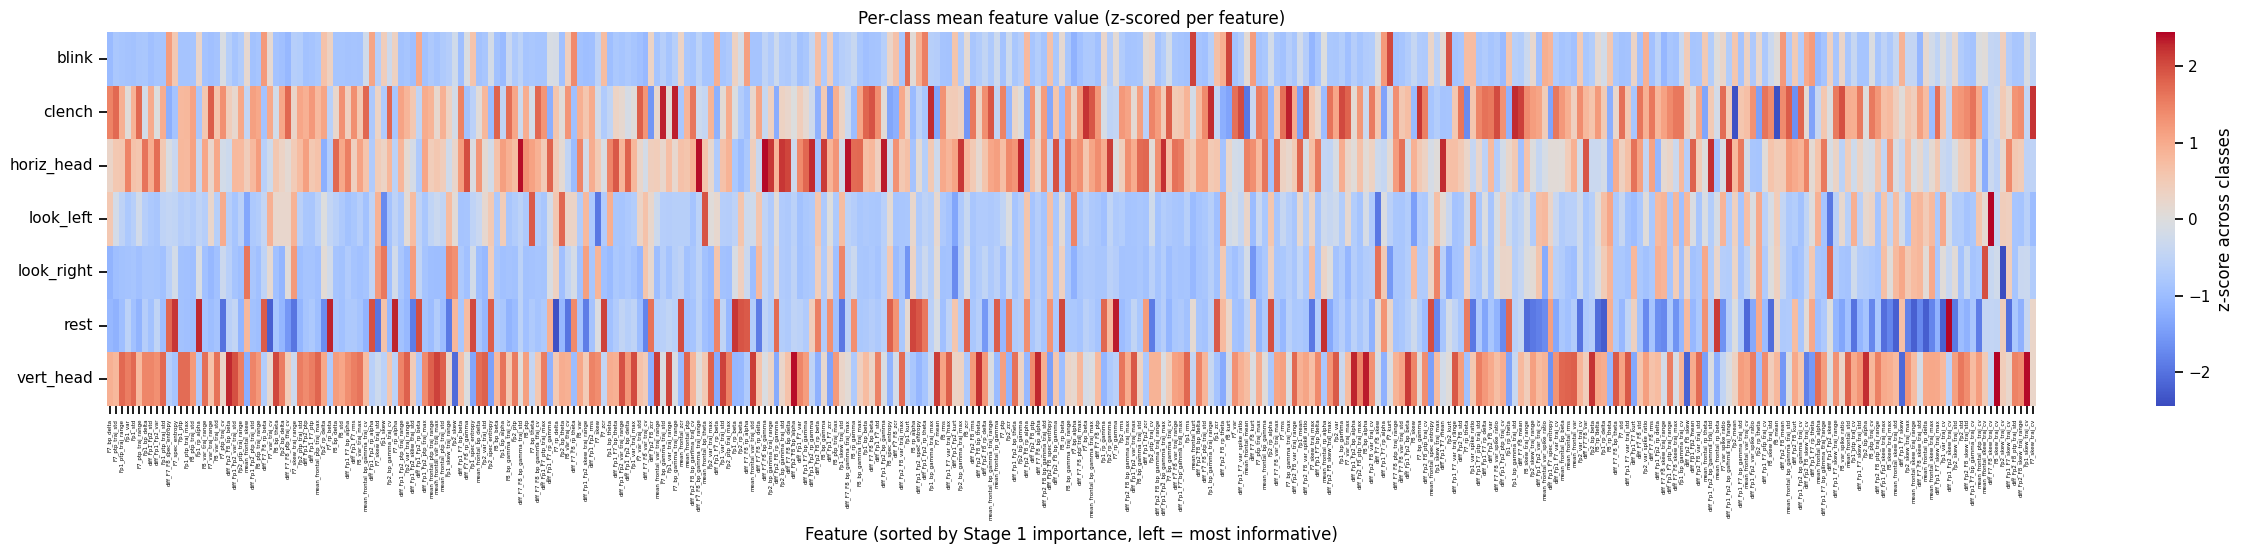

In [12]:
# ---- Per-class mean feature heatmap (descriptive only — affects no model) ----
fine_labels_for_heatmap = sorted(np.unique(y_fine).tolist())
per_class_means = np.vstack([
    X[y_fine == lbl].mean(axis=0) for lbl in fine_labels_for_heatmap
])

# Z-score each column (feature) so scales are comparable across features.
col_mean = per_class_means.mean(axis=0)
col_std  = per_class_means.std(axis=0) + 1e-12
zscored = (per_class_means - col_mean) / col_std

# Sort columns by Stage 1 mean importance (descending) so the most
# discriminative features appear on the left.
s1_mean_imp = np.vstack(stage_importances["stage1"]).mean(axis=0)
col_order = np.argsort(-s1_mean_imp)
zscored_sorted  = zscored[:, col_order]
features_sorted = [feature_names[i] for i in col_order]

fig, ax = plt.subplots(figsize=(min(28, 0.06 * len(features_sorted) + 6),
                                0.6 * len(fine_labels_for_heatmap) + 1.5))
sns.heatmap(zscored_sorted, cmap="coolwarm", center=0,
            xticklabels=features_sorted, yticklabels=fine_labels_for_heatmap,
            cbar_kws={"label": "z-score across classes"}, ax=ax)
ax.set_xlabel("Feature (sorted by Stage 1 importance, left = most informative)")
ax.set_title("Per-class mean feature value (z-scored per feature)")
ax.tick_params(axis="x", rotation=90, labelsize=4)
fig.tight_layout()
fig.savefig(CONFIG["OUTPUT_DIR"] / "xgb_per_class_feature_heatmap.png", dpi=160)
plt.show()

## Section 7 — Results summary

In [13]:
# ---- Model comparison (LOSO aggregate) ----
# Thresholding and RF chained come from CONFIG constants so the three approaches
# (thresholding, Random Forest, XGBoost) sit side by side.
comparison_df = pd.DataFrame([
    {"model": "Thresholding (binary)",
     "accuracy": CONFIG["THRESHOLDING_ACC"], "f1_macro": CONFIG["THRESHOLDING_F1"],
     "notes": "binary only; rules fitted on training rest"},
    {"model": "RF chained (03_RandomForest)",
     "accuracy": CONFIG["RF_CHAINED_ACC"], "f1_macro": CONFIG["RF_CHAINED_F1"],
     "notes": "Random Forest hierarchical pipeline"},
    {"model": "Flat XGBoost (7-class)",
     "accuracy": flat_acc, "f1_macro": flat_f1,
     "notes": "single XGBoost, balanced train"},
    {"model": "Stage 1 only",
     "accuracy": s1_acc, "f1_macro": s1_f1,
     "notes": f"XGBoost binary; ROC-AUC={s1_auc:.4f}"},
    {"model": "Stage 2",
     "accuracy": s2_acc, "f1_macro": s2_f1,
     "notes": "ocular vs head_muscle (true-label test windows)"},
    {"model": "Stage 3a (ocular)",
     "accuracy": s3a_acc, "f1_macro": s3a_f1,
     "notes": "blink / look_left / look_right"},
    {"model": "Stage 3b (head/musc)",
     "accuracy": s3b_acc, "f1_macro": s3b_f1,
     "notes": "horiz_head / vert_head / clench"},
    {"model": "XGBoost chained pipeline",
     "accuracy": chain_acc, "f1_macro": chain_f1,
     "notes": "Stage1 -> Stage2 -> Stage3a/3b"},
])
print(comparison_df.round(4).to_string(index=False))
comparison_df.to_csv(CONFIG["OUTPUT_DIR"] / "xgb_model_comparison.csv", index=False)

                       model  accuracy  f1_macro                                           notes
       Thresholding (binary)    0.7759    0.7706      binary only; rules fitted on training rest
RF chained (03_RandomForest)    0.7259    0.6196             Random Forest hierarchical pipeline
      Flat XGBoost (7-class)    0.7530    0.6522                  single XGBoost, balanced train
                Stage 1 only    0.8808    0.8808                  XGBoost binary; ROC-AUC=0.9538
                     Stage 2    0.9350    0.9350 ocular vs head_muscle (true-label test windows)
           Stage 3a (ocular)    0.8309    0.8309                  blink / look_left / look_right
        Stage 3b (head/musc)    0.6936    0.6921                 horiz_head / vert_head / clench
    XGBoost chained pipeline    0.7499    0.6576                  Stage1 -> Stage2 -> Stage3a/3b
